# **IMPORTING ESSENTIAL LIBRARIES**

In [ ]:
# Core Libraries
import pandas as pd
import numpy as np

# Visualization
import seaborn as sns
import seaborn as sns
import matplotlib.pyplot as plt

# Preprocessing, Modeling, Evaluation
from sklearn.preprocessing import LabelEncoder, StandardScaler,OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier,StackingClassifier

from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score,f1_score,roc_auc_score,precision_recall_curve,auc,roc_curve,log_loss,average_precision_score
from imblearn.over_sampling import SMOTE

# Statistical
from scipy.stats import chi2_contingency,skew

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Model saving/loading
import joblib
import os

# **LOADING DATASET**

In [ ]:
# prompt: mount from drive

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Load Dataset
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Bank_Fraud.csv")
df.head()

,Customer_ID,Customer_Name,Gender,Age,State,City,Bank_Branch,Account_Type,Transaction_ID,Transaction_Date,...,Merchant_Category,Account_Balance,Transaction_Device,Transaction_Location,Device_Type,Is_Fraud,Transaction_Currency,Customer_Contact,Transaction_Description,Customer_Email
0,d5f6ec07-d69e-4f47-b9b4-7c58ff17c19e,Osha Tella,Male,60,Kerala,Thiruvananthapuram,Thiruvananthapuram Branch,Savings,4fa3208f-9e23-42dc-b330-844829d0c12c,23-01-2025,...,Restaurant,74557.27,Voice Assistant,"Thiruvananthapuram, Kerala",POS,0,INR,+9198579XXXXXX,Bitcoin transaction,oshaXXXXX@XXXXX.com
1,7c14ad51-781a-4db9-b7bd-67439c175262,Hredhaan Khosla,Female,51,Maharashtra,Nashik,Nashik Branch,Business,c9de0c06-2c4c-40a9-97ed-3c7b8f97c79c,11-01-2025,...,Restaurant,74622.66,POS Mobile Device,"Nashik, Maharashtra",Desktop,0,INR,+9191074XXXXXX,Grocery delivery,hredhaanXXXX@XXXXXX.com
2,3a73a0e5-d4da-45aa-85f3-528413900a35,Ekani Nazareth,Male,20,Bihar,Bhagalpur,Bhagalpur Branch,Savings,e41c55f9-c016-4ff3-872b-cae72467c75c,25-01-2025,...,Groceries,66817.99,ATM,"Bhagalpur, Bihar",Desktop,0,INR,+9197745XXXXXX,Mutual fund investment,ekaniXXX@XXXXXX.com
3,7902f4ef-9050-4a79-857d-9c2ea3181940,Yamini Ramachandran,Female,57,Tamil Nadu,Chennai,Chennai Branch,Business,7f7ee11b-ff2c-45a3-802a-49bc47c02ecb,19-01-2025,...,Entertainment,58177.08,POS Mobile App,"Chennai, Tamil Nadu",Mobile,0,INR,+9195889XXXXXX,Food delivery,yaminiXXXXX@XXXXXXX.com
4,3a4bba70-d9a9-4c5f-8b92-1735fd8c19e9,Kritika Rege,Female,43,Punjab,Amritsar,Amritsar Branch,Savings,f8e6ac6f-81a1-4985-bf12-f60967d852ef,30-01-2025,...,Entertainment,16108.56,Virtual Card,"Amritsar, Punjab",Mobile,0,INR,+9195316XXXXXX,Debt repayment,kritikaXXXX@XXXXXX.com


# **EXPLORATORY DATA ANALYSIS & VISUALIZATION**

In [ ]:
# Number of Rows and Columns
df.shape

(200000, 24)

In [ ]:
# Creating a sample using 30% of data
df_sample = df.sample(frac=0.30, random_state=42)
df_sample.shape

(60000, 24)

In [ ]:
# Initial Inspection
df_sample.info()

<class 'pandas.core.frame.DataFrame'>
Index: 60000 entries, 119737 to 119389
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Customer_ID              60000 non-null  object 
 1   Customer_Name            60000 non-null  object 
 2   Gender                   60000 non-null  object 
 3   Age                      60000 non-null  int64  
 4   State                    60000 non-null  object 
 5   City                     60000 non-null  object 
 6   Bank_Branch              60000 non-null  object 
 7   Account_Type             60000 non-null  object 
 8   Transaction_ID           60000 non-null  object 
 9   Transaction_Date         60000 non-null  object 
 10  Transaction_Time         60000 non-null  object 
 11  Transaction_Amount       60000 non-null  float64
 12  Merchant_ID              60000 non-null  object 
 13  Transaction_Type         60000 non-null  object 
 14  Merchant_Category    

In [ ]:
# Statistics
df_sample.describe()

,Age,Transaction_Amount,Account_Balance,Is_Fraud
count,60000.000000,60000.000000,60000.000000,60000.000000
mean,44.044550,49562.575331,52239.035751,0.051183
std,15.294902,28621.032986,27291.381685,0.220373
min,18.000000,11.470000,5000.820000,0.000000
25%,31.000000,24696.585000,28784.867500,0.000000
50%,44.000000,49569.340000,52088.365000,0.000000
75%,57.000000,74507.482500,75691.692500,0.000000
max,70.000000,98999.980000,99998.680000,1.000000


**Dropping Irrelevant and Potentially Leaky features**


In [ ]:
# Dropping Irrelevant features
df_sample = df_sample.drop(columns=['Customer_ID', 'Customer_Name','Transaction_ID', 'Merchant_ID','Customer_Email','Customer_Contact','Transaction_Currency','Transaction_Date', 'Transaction_Time','Transaction_Description','Bank_Branch'])

**Check Missing Values**


In [ ]:
# Check missing values
print(df_sample.isnull().sum())

# Check duplicates
print(f"Duplicates: {df_sample.duplicated().sum()}")

Gender                  0
Age                     0
State                   0
City                    0
Account_Type            0
Transaction_Amount      0
Transaction_Type        0
Merchant_Category       0
Account_Balance         0
Transaction_Device      0
Transaction_Location    0
Device_Type             0
Is_Fraud                0
dtype: int64
Duplicates: 0


**Listing Categorical and Numerical Features**


In [ ]:
numerical_columns = df_sample.select_dtypes(include=['int64', 'float64']).columns
numerical_columns = numerical_columns.drop('Is_Fraud')
categorical_columns = df_sample.select_dtypes(include=['object']).columns
print(numerical_columns)
print(categorical_columns)

Index(['Age', 'Transaction_Amount', 'Account_Balance'], dtype='object')
Index(['Gender', 'State', 'City', 'Account_Type', 'Transaction_Type',
       'Merchant_Category', 'Transaction_Device', 'Transaction_Location',
       'Device_Type'],
      dtype='object')


In [ ]:
df_sample['Is_Fraud'].unique()

array([0, 1])

**Check Duplicate Rows and Columns**


In [ ]:
duplicate_rows = df_sample.duplicated()
print(f"Duplicate rows: {duplicate_rows.sum()}")

duplicate_columns = df_sample.T.duplicated()
print(f"Duplicate columns: {duplicate_columns.sum()}")

Duplicate rows: 0
Duplicate columns: 0


**Target and Feature Setup**


In [ ]:
target_col = 'Is_Fraud'
features = [col for col in df_sample.columns if col != target_col]

print("Target Column:", target_col)
print("Features:", features)

Target Column: Is_Fraud
Features: ['Gender', 'Age', 'State', 'City', 'Account_Type', 'Transaction_Amount', 'Transaction_Type', 'Merchant_Category', 'Account_Balance', 'Transaction_Device', 'Transaction_Location', 'Device_Type']


**Outlier Analysis**


In [ ]:
# IQR method to detect outliers
for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df_sample[(df_sample[col] < lower) | (df_sample[col] > upper)]
    print(f"{col}: {len(outliers)} outliers")

Age: 0 outliers
Transaction_Amount: 0 outliers
Account_Balance: 0 outliers


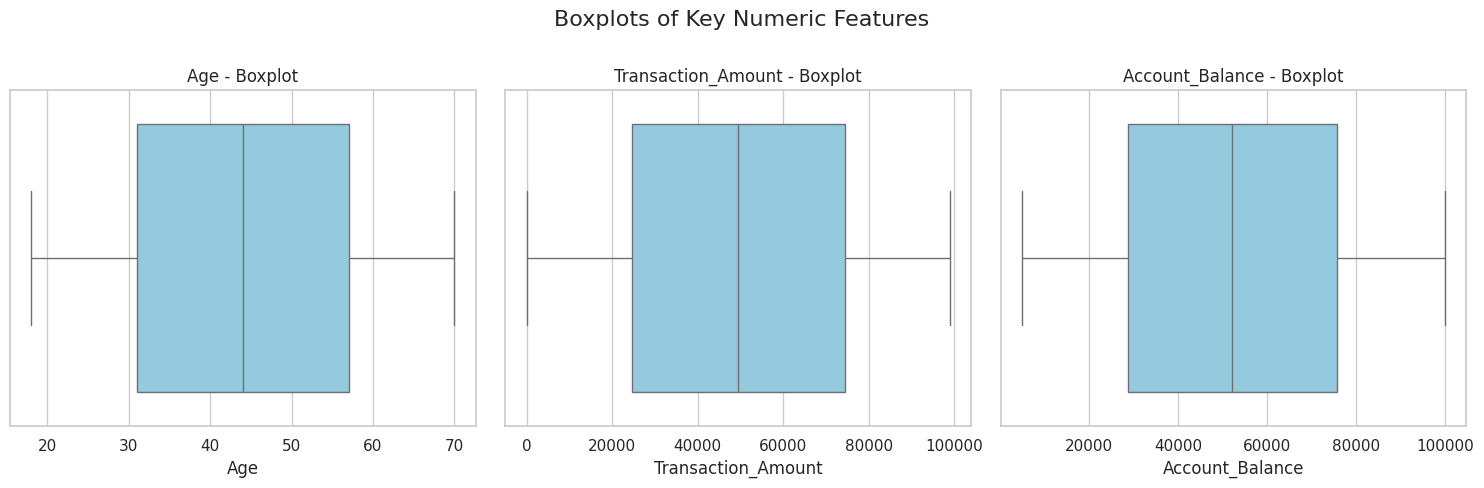

In [ ]:
# Box Plot Analysis
sns.set(style="whitegrid")
# Plot setup
plt.figure(figsize=(15, 8))
for i, col in enumerate(numerical_columns, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(data=df_sample, x=col, color='skyblue')
    plt.title(f'{col} - Boxplot')
    plt.tight_layout()

plt.suptitle('Boxplots of Key Numeric Features', fontsize=16, y=1.05)
plt.show()

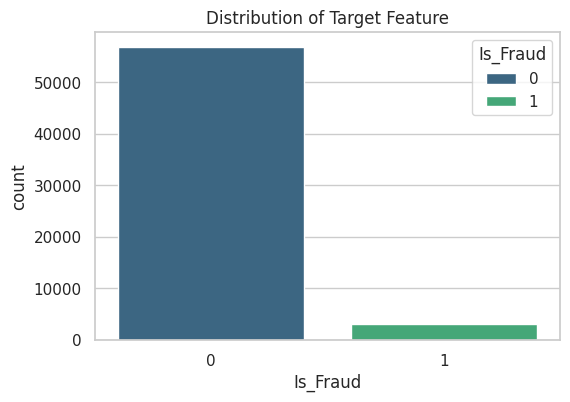

In [ ]:
# Target Feature Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df_sample, x='Is_Fraud',hue='Is_Fraud', palette='viridis')
plt.title('Distribution of Target Feature')
plt.show()

In [ ]:
# Unique values in Categorical Features
for col in categorical_columns:
    print(f"{col} unique values:", df_sample[col].unique())

Gender unique values: ['Female' 'Male']
State unique values: ['Manipur' 'Himachal Pradesh' 'Puducherry' 'Chandigarh' 'Gujarat'
 'Rajasthan' 'Goa' 'Kerala' 'Meghalaya' 'Nagaland' 'Uttar Pradesh'
 'Punjab' 'Telangana' 'Arunachal Pradesh' 'Tripura' 'Chhattisgarh'
 'Tamil Nadu' 'Bihar' 'Dadra and Nagar Haveli and Daman and Diu'
 'Andaman and Nicobar Islands' 'Delhi' 'Maharashtra' 'Jharkhand' 'Mizoram'
 'Lakshadweep' 'Assam' 'Odisha' 'Uttarakhand' 'West Bengal'
 'Andhra Pradesh' 'Haryana' 'Madhya Pradesh' 'Sikkim' 'Karnataka']
City unique values: ['Churachandpur' 'Shimla' 'Puducherry' 'Chandigarh' 'Ahmedabad' 'Udaipur'
 'Margao' 'Rajkot' 'Kozhikode' 'Tura' 'Wokha' 'Meerut' 'Patiala'
 'Karimnagar' 'Panaji' 'Kanpur' 'Tawang' 'Ambassa' 'Bilaspur' 'Salem'
 'Munger' 'Silvassa' 'Car Nicobar' 'Varanasi' 'Bhavnagar' 'North Delhi'
 'Kochi' 'Dimapur' 'Jagdalpur' 'Nashik' 'Aurangabad' 'Ranchi' 'Surat'
 'Aizawl' 'Ziro' 'Kavaratti' 'Naharlagun' 'Kolasib' 'Guwahati' 'Cuttack'
 'Dehradun' 'Jalandhar' 'Nag

In [ ]:
genders = df_sample['Gender'].unique()
states = df_sample['State'].unique()
cities = df_sample['City'].unique()
account_type = df_sample['Account_Type'].unique()
transaction_type = df_sample['Transaction_Type'].unique()
merchant_category = df_sample['Merchant_Category'].unique()
transaction_device = df_sample['Transaction_Device'].unique()
transaction_location = df_sample['Transaction_Location'].unique()
device_type = df_sample['Device_Type'].unique()

**Statistical Testing: Correlations**


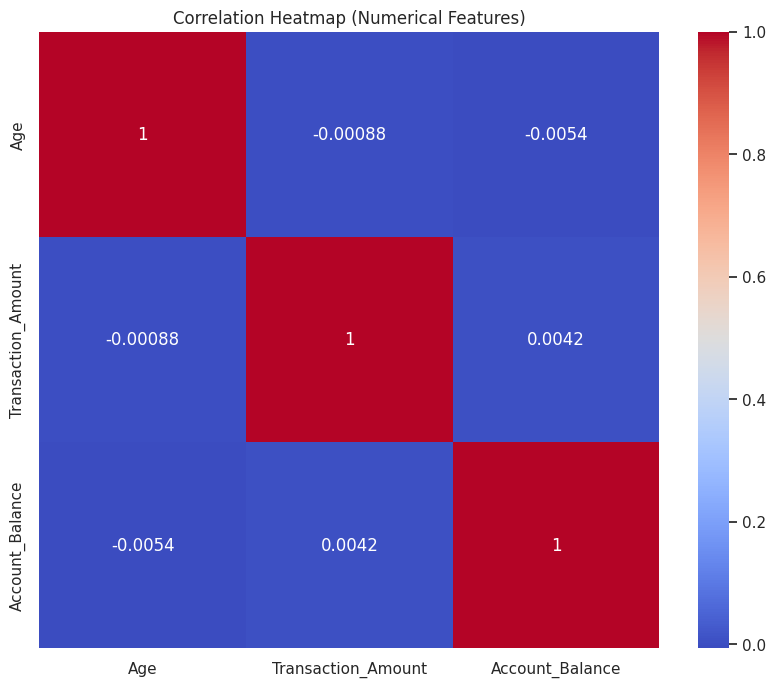

In [ ]:
# Correlation Matrix Heatmap (Numerical vs Numerical)
plt.figure(figsize=(10, 8))
corr = df_sample[numerical_columns].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap (Numerical Features)')
plt.show()

In [ ]:
# Encoding the Categorical features using Label Encoder

label_encoders = {}

for col in categorical_columns:
    le = LabelEncoder()
    df_sample[col] = le.fit_transform(df_sample[col])
    label_encoders[col] = le


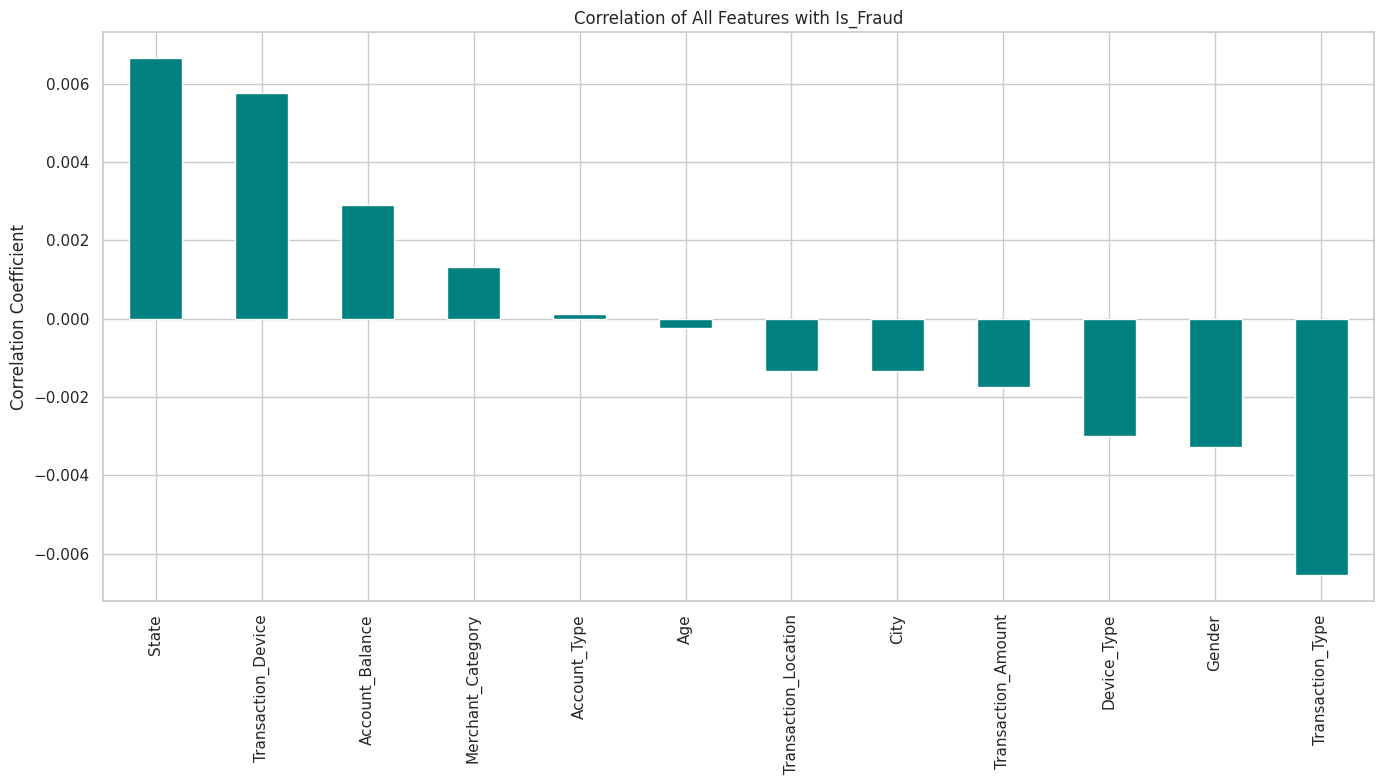

In [ ]:
cor_target = df_sample.corr()['Is_Fraud'].sort_values(ascending=False)
cor_target = cor_target.drop('Is_Fraud') # Dropped Target

# Plot the correlation
plt.figure(figsize=(14, 8))
cor_target.plot(kind='bar', color='teal')

# Plot settings
plt.title('Correlation of All Features with Is_Fraud')
plt.ylabel('Correlation Coefficient')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

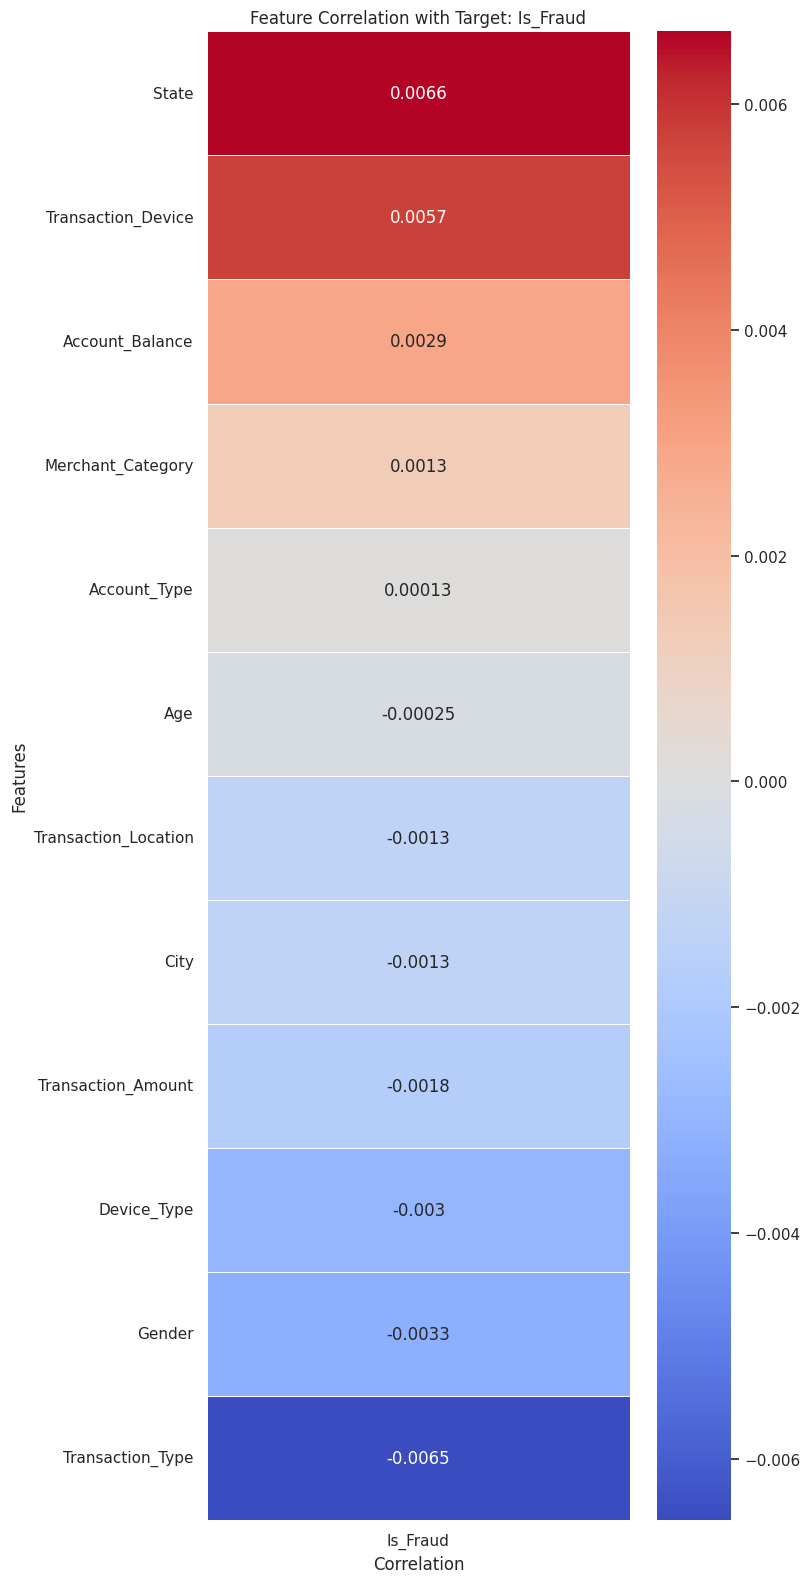

In [ ]:
# Ensure target is in the DataFrame
target_col = 'Is_Fraud'

# Compute correlation matrix with target
correlation_with_target = df_sample.corr()[[target_col]].sort_values(by=target_col, ascending=False)

# Drop the target itself (optional)
correlation_with_target = correlation_with_target.drop(index=target_col)

# Plot heatmap
plt.figure(figsize=(8, 16))
sns.heatmap(correlation_with_target, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title(f'Feature Correlation with Target: {target_col}')
plt.xlabel('Correlation')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


In [ ]:
# Training and Test Data
X = df_sample.drop(columns=['Is_Fraud'])
y = df_sample['Is_Fraud']

smt = SMOTE(random_state=42)
X_resampled, y_resampled = smt.fit_resample(X, y)

# Use y_resampled for stratification
X_train, X_test, y_train, y_test = train_test_split(
    X_resampled, y_resampled, stratify=y_resampled, test_size=0.2, random_state=42
)

# standardize
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# Shape after Over Sampling
X_resampled = X_resampled.shape
y_resampled = y_resampled.shape
print(X_resampled)
print(y_resampled)

(113858, 12)
(113858,)


In [ ]:
# Define models
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Random Forest": RandomForestClassifier(class_weight='balanced',random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
    "LightGBM": LGBMClassifier(random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    results.append((name, accuracy))
    print(f"\n{name} Results:")
    print(f"Accuracy: {accuracy:.4f}")
    print(classification_report(y_test, y_pred))



Logistic Regression Results:
Accuracy: 0.6724
              precision    recall  f1-score   support

           0       0.68      0.65      0.67     11386
           1       0.67      0.69      0.68     11386

    accuracy                           0.67     22772
   macro avg       0.67      0.67      0.67     22772
weighted avg       0.67      0.67      0.67     22772


Random Forest Results:
Accuracy: 0.9028
              precision    recall  f1-score   support

           0       0.92      0.88      0.90     11386
           1       0.88      0.93      0.91     11386

    accuracy                           0.90     22772
   macro avg       0.90      0.90      0.90     22772
weighted avg       0.90      0.90      0.90     22772


Gradient Boosting Results:
Accuracy: 0.7765
              precision    recall  f1-score   support

           0       0.80      0.74      0.77     11386
           1       0.76      0.81      0.78     11386

    accuracy                           0.78     2

In [ ]:
res_df = pd.DataFrame(results, columns=["Model", "Accuracy"])

# Sort results by accuracy
res_df = res_df.sort_values(by=["Accuracy"], ascending=[False])

# Display the sorted results
res_df

,Model,Accuracy
6,XGBoost,0.916608
1,Random Forest,0.902819
4,Decision Tree,0.866371
7,LightGBM,0.840374
8,K-Nearest Neighbors,0.812972
9,Neural Network (MLP),0.779554
2,Gradient Boosting,0.776524
3,AdaBoost,0.747541
5,Naive Bayes,0.738231
0,Logistic Regression,0.672361


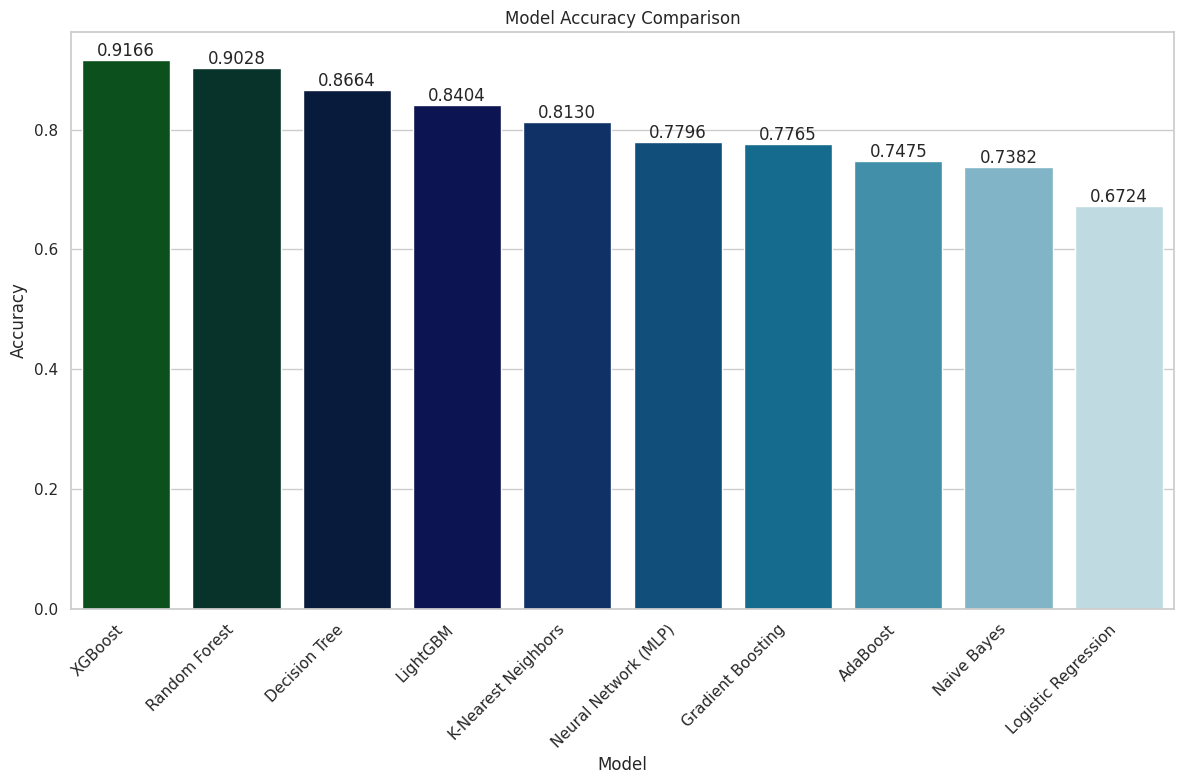

In [ ]:
plt.figure(figsize=(12, 8))
ax = sns.barplot(data=res_df, x="Model", y="Accuracy", palette="ocean")
plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.xticks(rotation=45, ha='right')
plt.ylabel("Accuracy")

# Add accuracy values on top of each bar
for i, v in enumerate(res_df['Accuracy']):
    ax.text(i, v, f'{v:.4f}', ha='center', va='bottom')

# Adjust layout to prevent cutting off labels
plt.tight_layout()

plt.show()

In [ ]:
# Best Model
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb_model.fit(X_train, y_train)

# Predictions
y_pred_rf = xgb_model.predict(X_test)
y_probs_rf = xgb_model.predict_proba(X_test)[:, 1]

# Evaluation metrics
precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_probs_rf)

print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print()
print(f"Recall: {recall_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_rf):.4f}")
print(f"ROC AUC: {roc_auc_score(y_test, y_probs_rf):.4f}")
print(f"PR AUC: {auc(recall_vals, precision_vals):.4f}")
print(f"Log Loss: {log_loss(y_test, y_probs_rf):.4f}")


Accuracy: 0.9166

Recall: 0.9046
Precision: 0.9268
F1 Score: 0.9156
ROC AUC: 0.9667
PR AUC: 0.9748
Log Loss: 0.2466


<Axes: >

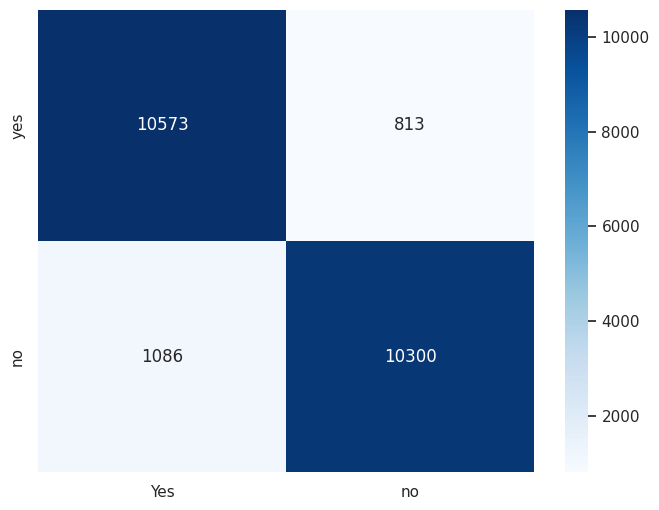

In [ ]:
# Confusion Matrix
cn = confusion_matrix(y_test, y_pred_rf)

# Plot Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cn, annot=True, fmt='d', cmap='Blues', xticklabels=['Yes', 'no'], yticklabels=['yes', 'no'])

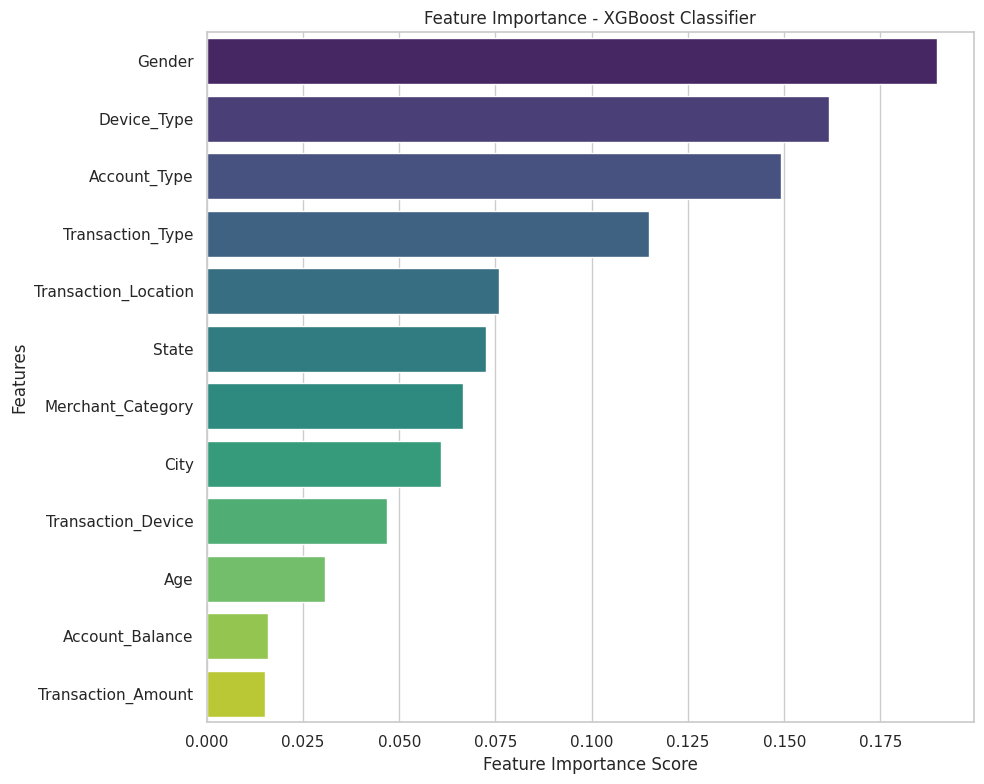

In [ ]:
# Get feature importances and feature names
importances = xgb_model.feature_importances_

# Get the feature names from the original DataFrame X before scaling
feature_names = X.columns

# Create a DataFrame for sorting
feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(10, 8))
sns.barplot(data=feat_imp_df, x='Importance', y='Feature', palette='viridis')
plt.title('Feature Importance - XGBoost Classifier')
plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [ ]:
# Save the XGB model
joblib.dump(xgb_model, 'xgb_model.pkl')

['xgb_model.pkl']

In [ ]:
#training features
joblib.dump(X.columns.tolist(), 'feature_columns.pkl')

['feature_columns.pkl']

In [ ]:
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

# **TESTING**

In [ ]:
import ipywidgets as widgets
from IPython.display import display
import pandas as pd
import joblib

# --- Load saved components ---
model = joblib.load("xgb_model.pkl")
features = joblib.load("feature_columns.pkl")
scaler = joblib.load("scaler.pkl")
# label_encoders = joblib.load("label_encoders.pkl")  # Dict of LabelEncoders



# --- Define categorical column names (must match training) ---
categorical_columns = ['Gender', 'State', 'City', 'Account_Type', 'Transaction_Type',
                       'Merchant_Category', 'Transaction_Device', 'Transaction_Location', 'Device_Type']

# --- Define your dropdown options (e.g., extracted from training set or hardcoded) ---
genders = list(label_encoders['Gender'].classes_)
states = list(label_encoders['State'].classes_)
cities = list(label_encoders['City'].classes_)
account_type = list(label_encoders['Account_Type'].classes_)
transaction_type = list(label_encoders['Transaction_Type'].classes_)
merchant_category = list(label_encoders['Merchant_Category'].classes_)
transaction_device = list(label_encoders['Transaction_Device'].classes_)
transaction_location = list(label_encoders['Transaction_Location'].classes_)
device_type = list(label_encoders['Device_Type'].classes_)

# --- Create widgets ---
gender = widgets.Dropdown(options=genders, description='Gender:')
state = widgets.Dropdown(options=states, description='State:')
city = widgets.Dropdown(options=cities, description='City:')
acc_type = widgets.Dropdown(options=account_type, description='Account Type:')
txn_type = widgets.Dropdown(options=transaction_type, description='Transaction Type:')
merchant_cat = widgets.Dropdown(options=merchant_category, description='Merchant Category:')
txn_device = widgets.Dropdown(options=transaction_device, description='Transaction Device:')
txn_location = widgets.Dropdown(options=transaction_location, description='Location:')
dev_type = widgets.Dropdown(options=device_type, description='Device Type:')
age = widgets.IntSlider(min=18, max=100, value=30, description='Age:')
amount = widgets.FloatText(value=1000.0, description='Amount:')
balance = widgets.FloatText(value=5000.0, description='Balance:')

# --- Display widgets ---
display(gender, state, city, acc_type, txn_type, merchant_cat, txn_device,
        txn_location, dev_type, age, amount, balance)

# --- Predict button ---
button = widgets.Button(description="Predict", button_style='info')

# --- Prediction function ---
def on_button_click(b):
    # Collect input values
    sample = {
        'Gender': gender.value,
        'State': state.value,
        'City': city.value,
        'Account_Type': acc_type.value,
        'Transaction_Type': txn_type.value,
        'Merchant_Category': merchant_cat.value,
        'Transaction_Device': txn_device.value,
        'Transaction_Location': txn_location.value,
        'Device_Type': dev_type.value,
        'Age': age.value,
        'Transaction_Amount': amount.value,
        'Account_Balance': balance.value
    }

    df_input = pd.DataFrame([sample])

    # Label Encoding for categorical columns
    for col in categorical_columns:
        le = label_encoders[col]
        val = df_input[col][0]
        if val not in le.classes_:
            print(f"⚠️ Unknown value '{val}' in column '{col}'. Please choose a valid option.")
            return
        df_input[col] = le.transform([val])

    # Ensure correct column order
    df_input = df_input[features]  # same as training set

    # Scale
    df_scaled = scaler.transform(df_input)

    # Predict
    prediction = model.predict(df_scaled)[0]
    result = "🛑 Fraudulent" if prediction == 1 else "✅ Legitimate"
    print("Prediction:", result)

# --- Bind and show ---
button.on_click(on_button_click)
display(button)

Dropdown(description='Gender:', options=('Female', 'Male'), value='Female')

Dropdown(description='State:', options=('Andaman and Nicobar Islands', 'Andhra Pradesh', 'Arunachal Pradesh', …

Dropdown(description='City:', options=('Agartala', 'Agra', 'Ahmedabad', 'Aizawl', 'Ajmer', 'Ambala', 'Ambassa'…

Dropdown(description='Account Type:', options=('Business', 'Checking', 'Savings'), value='Business')

Dropdown(description='Transaction Type:', options=('Bill Payment', 'Credit', 'Debit', 'Transfer', 'Withdrawal'…

Dropdown(description='Merchant Category:', options=('Clothing', 'Electronics', 'Entertainment', 'Groceries', '…

... (4 outputs left out)

FloatText(value=1000.0, description='Amount:')

FloatText(value=5000.0, description='Balance:')

Button(button_style='info', description='Predict', style=ButtonStyle())

Prediction: ✅ Legitimate
Prediction: ✅ Legitimate
Prediction: ✅ Legitimate
Prediction: ✅ Legitimate
Prediction: ✅ Legitimate
Prediction: ✅ Legitimate
Prediction: 🛑 Fraudulent
Prediction: 🛑 Fraudulent
Prediction: 🛑 Fraudulent
Prediction: 🛑 Fraudulent
Prediction: 🛑 Fraudulent
